# EMIPredict AI — Exploratory Data Analysis (EDA)

Comprehensive exploration of customer demographics, financial obligations, credit metrics, and target distributions across the 404,800-record dataset.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configure styles
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Path setup
DATA_PATH = Path('../data/emi_prediction_dataset.csv')
FIGURES_DIR = Path('../reports/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Add src to sys.path
sys.path.append(str(Path('..').resolve()))
from src.data_preprocessing import load_and_clean_data
from src.feature_engineering import calculate_financial_indicators

print("Libraries imported successfully!")


Libraries imported successfully!


## 1. Load and Clean Dataset
Leverages the robust `src.data_preprocessing.load_and_clean_data` module to parse numeric values, fix string formatting artifacts (e.g. `58.0.0`), and normalize categorical features like `gender`.

In [2]:
df = load_and_clean_data(DATA_PATH)
df = calculate_financial_indicators(df)

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
display(df[['age', 'gender', 'monthly_salary', 'credit_score', 'emi_eligibility', 'max_monthly_emi']].head(5))


Dataset Shape: 404,800 rows, 36 columns


,age,gender,monthly_salary,credit_score,emi_eligibility,max_monthly_emi
0,38.0,Female,82600.0,660.0,Not_Eligible,500.0
1,38.0,Female,21500.0,714.0,Not_Eligible,700.0
2,38.0,Male,86100.0,650.0,Eligible,27775.0
3,58.0,Female,66800.0,685.0,Eligible,16170.0
4,48.0,Female,57300.0,770.0,Not_Eligible,500.0


## 2. Target Distributions
- **Classification Target:** `emi_eligibility` (`Not_Eligible`, `Eligible`, `High_Risk`)
- **Regression Target:** `max_monthly_emi` (Continuous ₹ value)

C:\Users\Rahul Kiran Hosuru\AppData\Local\Temp\ipykernel_10492\4124024886.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=['#1f77b4', '#2ca02c', '#d62728'])


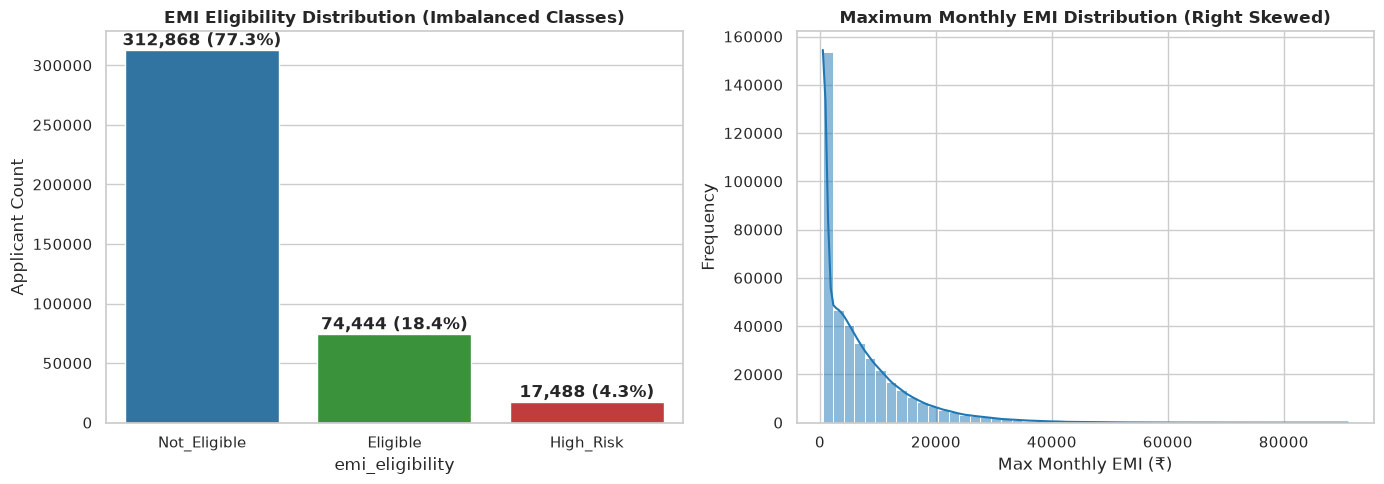

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Classification target distribution
counts = df['emi_eligibility'].value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=axes[0], palette=['#1f77b4', '#2ca02c', '#d62728'])
axes[0].set_title('EMI Eligibility Distribution (Imbalanced Classes)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Applicant Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 4000, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Regression target distribution
sns.histplot(df['max_monthly_emi'], bins=50, kde=True, ax=axes[1], color='#1f77b4')
axes[1].set_title('Maximum Monthly EMI Distribution (Right Skewed)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Max Monthly EMI (₹)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '1_target_distributions.png', dpi=150)
plt.show()


## 3. Correlation Heatmap of Numerical Features
Visualizes Pearson correlations between income, monthly living expenses, debt burdens, and the maximum allowable monthly EMI.

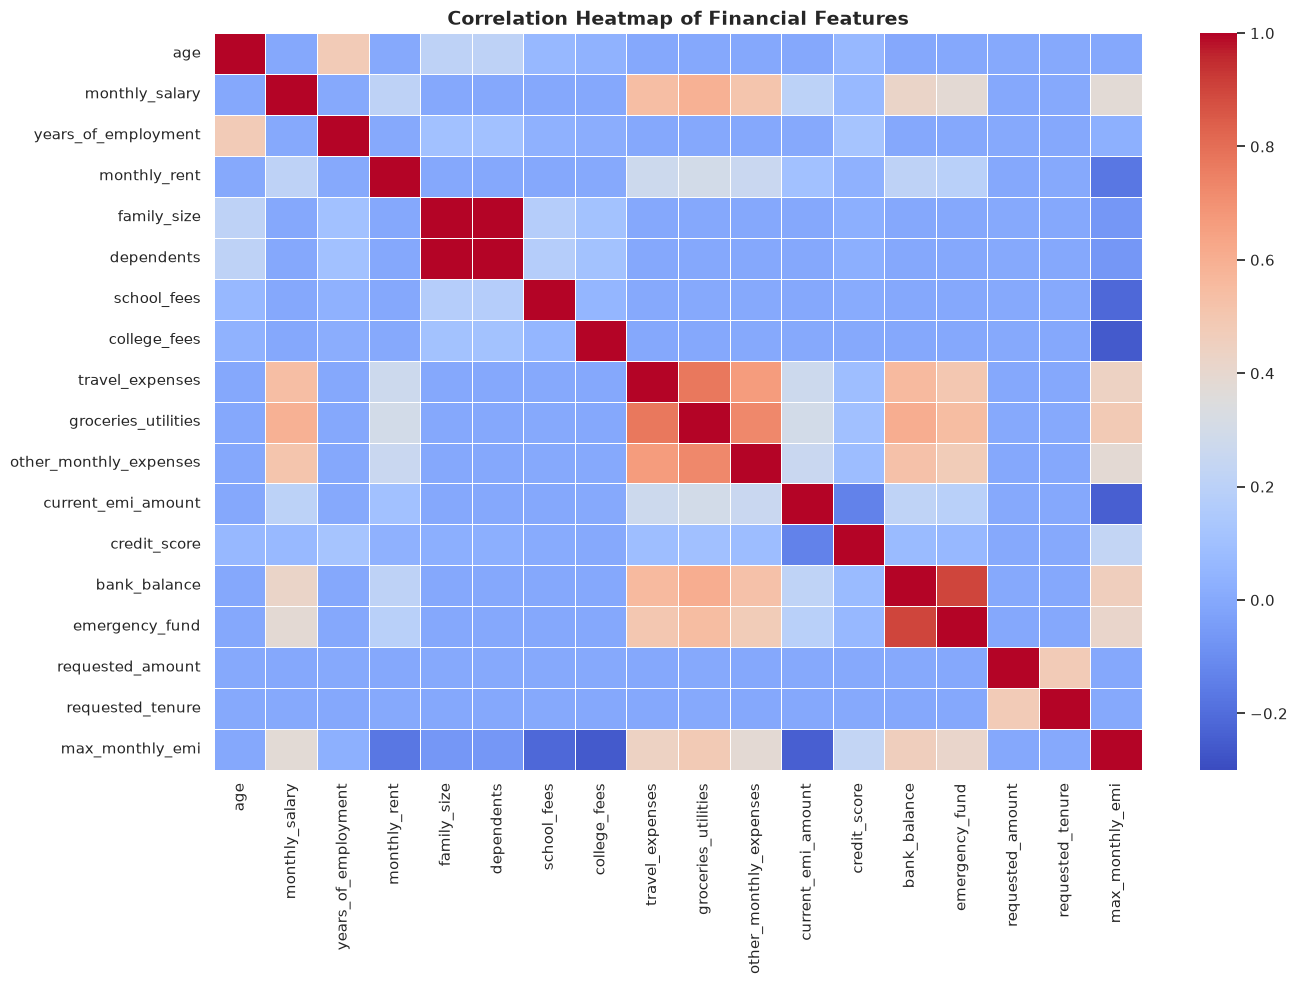

In [4]:
num_cols = [
    'age', 'monthly_salary', 'years_of_employment', 'monthly_rent',
    'family_size', 'dependents', 'school_fees', 'college_fees',
    'travel_expenses', 'groceries_utilities', 'other_monthly_expenses',
    'current_emi_amount', 'credit_score', 'bank_balance', 'emergency_fund',
    'requested_amount', 'requested_tenure', 'max_monthly_emi'
]

corr = df[num_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap='coolwarm', annot=False, vmin=-0.3, vmax=1.0, linewidths=0.5)
plt.title('Correlation Heatmap of Financial Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '2_correlation_heatmap.png', dpi=150)
plt.show()


## 4. Maximum Monthly EMI Across Loan Scenarios

C:\Users\Rahul Kiran Hosuru\AppData\Local\Temp\ipykernel_10492\56511468.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='emi_scenario', y='max_monthly_emi', palette='Blues', showfliers=False)


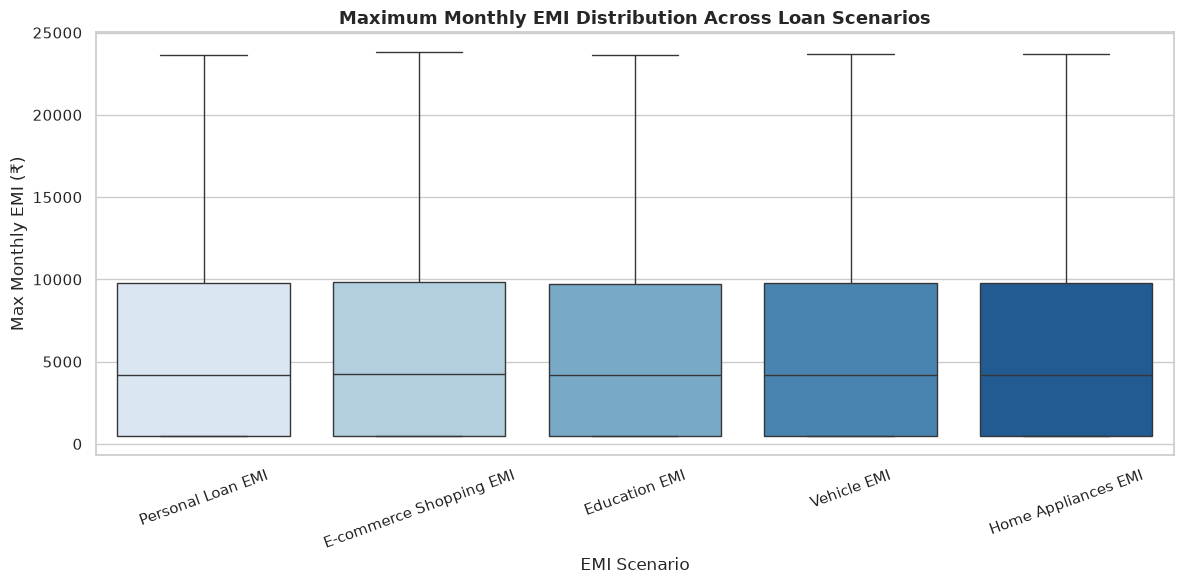

In [5]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='emi_scenario', y='max_monthly_emi', palette='Blues', showfliers=False)
plt.title('Maximum Monthly EMI Distribution Across Loan Scenarios', fontsize=13, fontweight='bold')
plt.xlabel('EMI Scenario')
plt.ylabel('Max Monthly EMI (₹)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIGURES_DIR / '3_max_emi_by_scenario.png', dpi=150)
plt.show()


## 5. Monthly Salary and Debt Ratios by Eligibility

C:\Users\Rahul Kiran Hosuru\AppData\Local\Temp\ipykernel_10492\3529067212.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='emi_eligibility', y='monthly_salary', showfliers=False, ax=axes[0], palette=['#1f77b4', '#2ca02c', '#d62728'])


C:\Users\Rahul Kiran Hosuru\AppData\Local\Temp\ipykernel_10492\3529067212.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='emi_eligibility', y='debt_to_income_ratio', showfliers=False, ax=axes[1], palette=['#1f77b4', '#2ca02c', '#d62728'])


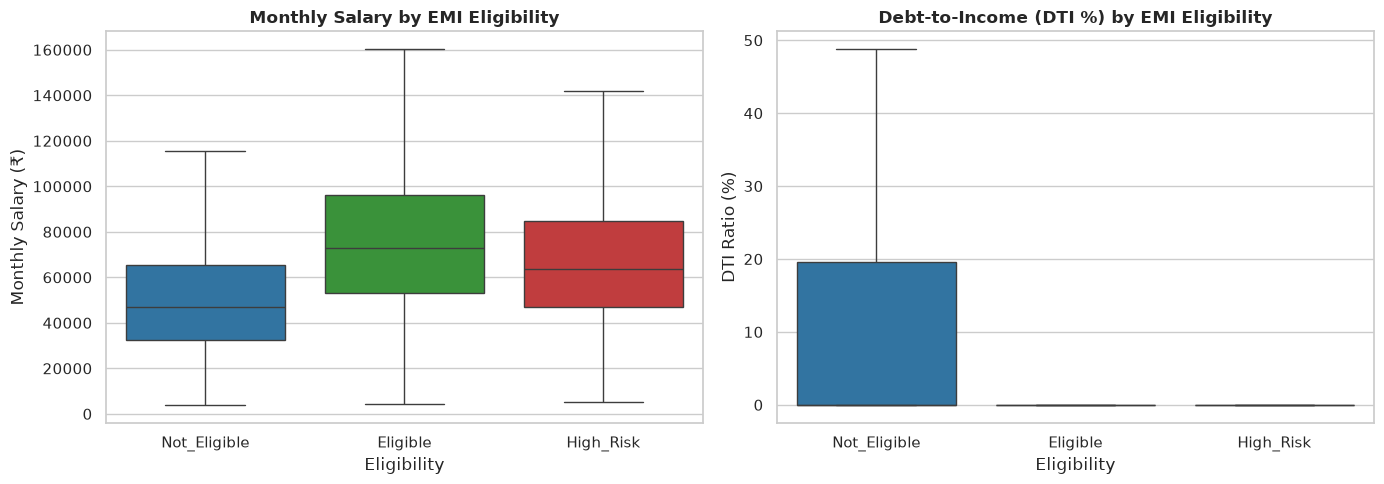

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Salary by eligibility
sns.boxplot(data=df, x='emi_eligibility', y='monthly_salary', showfliers=False, ax=axes[0], palette=['#1f77b4', '#2ca02c', '#d62728'])
axes[0].set_title('Monthly Salary by EMI Eligibility', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Eligibility')
axes[0].set_ylabel('Monthly Salary (₹)')

# DTI by eligibility
sns.boxplot(data=df, x='emi_eligibility', y='debt_to_income_ratio', showfliers=False, ax=axes[1], palette=['#1f77b4', '#2ca02c', '#d62728'])
axes[1].set_title('Debt-to-Income (DTI %) by EMI Eligibility', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Eligibility')
axes[1].set_ylabel('DTI Ratio (%)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '4_salary_and_dti_by_eligibility.png', dpi=150)
plt.show()


## 6. Key Business & Analytical Insights

1. **Severe Class Imbalance:** `Not_Eligible` comprises 77.3% of the dataset, while `Eligible` represents 18.4% and `High_Risk` only 4.3%. Standard unweighted classifiers will naturally predict the majority class, which is unacceptable in lending risk assessment.
2. **Salary and Disposable Income:** Strong positive correlation with maximum allowable monthly EMI.
3. **Debt Burdens:** Higher existing EMI commitments and rental expenses significantly depress safe debt capacity.